# Semiconductor equity analysis

Assess common variation in NVDA, AMD, AVGO, TSM, MU, INTC, and ASML returns, and how much remains after controlling for
the broad market.

Initial benchmark: SPY.

In [72]:
%pip install yfinance
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [73]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import yfinance as yf

In [74]:
equity_groups = {
    "designers": ["NVDA", "AMD", "AVGO"],
    "manufacturers": ["TSM", "MU", "INTC"],  
    "equipment": ["ASML"],
}

equity_tickers = [
    ticker
    for tickers in equity_groups.values()
    for ticker in tickers
]

benchmark_ticker = "SPY"

In [75]:
tickers = equity_tickers + [benchmark_ticker]

prices = yf.download(
    tickers=tickers,
    start="2010-01-01",
    end="2023-01-01",
    interval="1d",
    auto_adjust=False,
    actions=True,
    keepna=True,
    repair=False,
)

[*********************100%***********************]  8 of 8 completed


In [76]:
prices.shape

(3272, 65)

In [77]:
prices.head()

Price      Adj Close                                                       \
Ticker           AMD       ASML      AVGO       INTC         MU      NVDA   
Date                                                                        
2010-01-04      9.70  32.228188  1.321281  13.519423  10.578575  0.422817   
2010-01-05      9.71  32.479244  1.331089  13.512953  10.890566  0.428991   
2010-01-06      9.57  32.776794  1.341597  13.467627  10.939317  0.431736   
2010-01-07      9.47  31.865549  1.333190  13.338132  10.568826  0.423275   
2010-01-08      9.43  31.103069  1.342999  13.487051  10.822319  0.424189   

Price                           Capital Gains Close  ... Stock Splits       \
Ticker            SPY       TSM           SPY   AMD  ...          SPY  TSM   
Date                                                 ...                     
2010-01-04  84.368965  7.199557           0.0  9.70  ...          0.0  0.0   
2010-01-05  84.592316  7.168467           0.0  9.71  ...          0.0  0.0   
2010-01-06  84.651878  7.143602           0.0  9.57  ...          0.0  0.0   
2010-01-07  85.009224  6.907347           0.0  9.47  ...          0.0  0.0   
2010-01-08  85.292091  6.901131           0.0  9.43  ...          0.0  0.0   

Price         Volume                                                   \
Ticker           AMD     ASML     AVGO      INTC        MU       NVDA   
Date                                                                    
2010-01-04  18748700  1390235  5387000  47800900  34412700  800204000   
2010-01-05  22145700  1094016  3011000  52357700  60659000  728648000   
2010-01-06  18643400  1051204  5331000  40037400  32060400  649168000   
2010-01-07  26806800  2057440  2718000  54041500  46461800  547792000   
2010-01-08  13752800  3027178  2899000  48234700  32433400  478168000   

Price                            
Ticker            SPY       TSM  
Date                             
2010-01-04  118944600   8096400  
2010-01-05  111579900  14375900  
2010-01-06  116074400  13608400  
2010-01-07  131091100  27346600  
2010-01-08  126402800  16895300  

[5 rows x 65 columns]

In [78]:
adjusted_close = prices["Adj Close"].copy()

data_check = pd.DataFrame({
    "first_date": adjusted_close.apply(
        lambda column: column.first_valid_index()
    ),
    "last_date": adjusted_close.apply(
        lambda column: column.last_valid_index()
    ),
    "missing_prices": adjusted_close.isna().sum(),
})

display(data_check)

print("Dates in order:", adjusted_close.index.is_monotonic_increasing)
print("Duplicate dates:", adjusted_close.index.has_duplicates)

,first_date,last_date,missing_prices
Ticker,,,
AMD,2010-01-04,2022-12-30,0
ASML,2010-01-04,2022-12-30,0
AVGO,2010-01-04,2022-12-30,0
INTC,2010-01-04,2022-12-30,0
MU,2010-01-04,2022-12-30,0
NVDA,2010-01-04,2022-12-30,0
SPY,2010-01-04,2022-12-30,0
TSM,2010-01-04,2022-12-30,0


Dates in order: True
Duplicate dates: False


In [79]:
returns = adjusted_close.pct_change(fill_method=None).iloc[1:]

In [80]:
returns.describe().T

,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
AMD,3271.0,0.001214,0.035865,-0.242291,-0.017180,0.000000,0.018542,0.522901
ASML,3271.0,0.001093,0.021806,-0.173491,-0.010148,0.000979,0.012685,0.145732
AVGO,3271.0,0.001380,0.022339,-0.199129,-0.010247,0.001490,0.012774,0.158337
INTC,3271.0,0.000368,0.018603,-0.180415,-0.008481,0.000467,0.009441,0.195213
MU,3271.0,0.000921,0.030024,-0.198186,-0.015171,0.000756,0.017505,0.234432
NVDA,3271.0,0.001474,0.028083,-0.187559,-0.012102,0.001447,0.015085,0.298067
SPY,3271.0,0.000509,0.011094,-0.109424,-0.003731,0.000654,0.005748,0.090603
TSM,3271.0,0.000865,0.018314,-0.140341,-0.009198,0.000764,0.010561,0.126523


In [81]:
returns.head()

Ticker,AMD,ASML,AVGO,INTC,MU,NVDA,SPY,TSM
Date,,,,,,,,
2010-01-05,0.001031,0.007790,0.007423,-0.000479,0.029493,0.014602,0.002647,-0.004318
2010-01-06,-0.014418,0.009161,0.007895,-0.003354,0.004476,0.006397,0.000704,-0.003469
2010-01-07,-0.010449,-0.027802,-0.006266,-0.009615,-0.033868,-0.019598,0.004221,-0.033072
2010-01-08,-0.004224,-0.023928,0.007357,0.011165,0.023985,0.002161,0.003327,-0.000900
2010-01-11,-0.030753,-0.021225,0.006260,0.005761,-0.018018,-0.014016,0.001396,-0.005406


Now we calculate the pearson correlation matrix for the tickers

In [82]:
returns_correlation_matrix = returns.corr()
returns_correlation_matrix

Ticker,AMD,ASML,AVGO,INTC,MU,NVDA,SPY,TSM
Ticker,,,,,,,,
AMD,1.000000,0.441542,0.405989,0.416588,0.468813,0.550736,0.507432,0.433108
ASML,0.441542,1.000000,0.581688,0.571128,0.547588,0.583158,0.686337,0.614186
AVGO,0.405989,0.581688,1.000000,0.530823,0.524627,0.530774,0.640952,0.525534
INTC,0.416588,0.571128,0.530823,1.000000,0.555420,0.538908,0.678344,0.523603
MU,0.468813,0.547588,0.524627,0.555420,1.000000,0.556451,0.607576,0.527275
NVDA,0.550736,0.583158,0.530774,0.538908,0.556451,1.000000,0.632650,0.545651
SPY,0.507432,0.686337,0.640952,0.678344,0.607576,0.632650,1.000000,0.623230
TSM,0.433108,0.614186,0.525534,0.523603,0.527275,0.545651,0.623230,1.000000


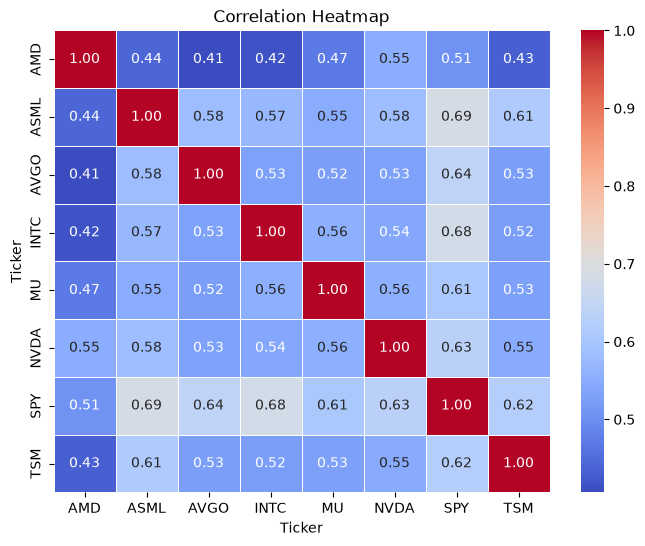

In [92]:
plt.figure(figsize=(8,6))
sns.heatmap(returns_correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

# Do semiconductor stocks share a common return component?

We want to measure how much co-movement remains after accounting for SPY movements, we do so by fitting $r_{i,t} = \alpha_i + \beta_i \cdot r_{SPY, t} + \varepsilon _{i,t}$ using OLS 




In [113]:
residuals = {}

for ticker in equity_tickers:
    regression_data = returns[[ticker, "SPY"]].dropna()
    y = regression_data[ticker]
    X = sm.add_constant(regression_data["SPY"])
    model = sm.OLS(y, X)
    result = model.fit()
    print(f"{ticker} - "f"Alpha: {result.params['const']:.6f}, "f"Beta: {result.params['SPY']:.4f}, "f"R-squared: {result.rsquared:.4f}")
    residuals[ticker] = result.resid


NVDA - Alpha: 0.000658, Beta: 1.6014, R-squared: 0.4002
AMD - Alpha: 0.000378, Beta: 1.6404, R-squared: 0.2575
AVGO - Alpha: 0.000723, Beta: 1.2906, R-squared: 0.4108
TSM - Alpha: 0.000341, Beta: 1.0288, R-squared: 0.3884
MU - Alpha: 0.000083, Beta: 1.6443, R-squared: 0.3691
INTC - Alpha: -0.000212, Beta: 1.1375, R-squared: 0.4602
ASML - Alpha: 0.000406, Beta: 1.3490, R-squared: 0.4711


In [114]:
residuals_df = pd.DataFrame(residuals)
residuals_df.head()

,NVDA,AMD,AVGO,TSM,MU,INTC,ASML
Date,,,,,,,
2010-01-05,0.009705,-0.003690,0.003284,-0.007383,0.025056,-0.003278,0.003813
2010-01-06,0.004611,-0.015951,0.006263,-0.004534,0.003235,-0.003943,0.007806
2010-01-07,-0.027016,-0.017752,-0.012437,-0.037757,-0.040892,-0.014205,-0.033902
2010-01-08,-0.003826,-0.010061,0.002340,-0.004664,0.018430,0.007592,-0.028823
2010-01-11,-0.016911,-0.033422,0.003735,-0.007183,-0.020397,0.004384,-0.023515


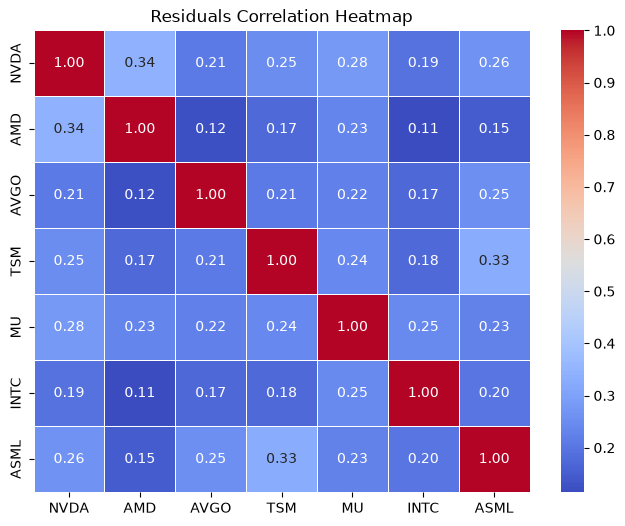

In [116]:
residuals_correlation_matrix = residuals_df.corr()

plt.figure(figsize=(8,6))
sns.heatmap(residuals_correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Residuals Correlation Heatmap")
plt.show()